# Unidad 5 · Actividad 2
## Proyecto integrador: solución secuencial aplicada

**Caso:** clasificación automática del sentimiento en reseñas de *Amazon Fine Food Reviews*.

**Integrantes:** Kinan El Halabi Jaber, Joel Montenegro González y Valentina Ramírez Puerto.

Este notebook integra los artefactos de las unidades anteriores. Carga el modelo BiGRU + Atención ya entrenado, aplica a reseñas nuevas el mismo preprocesamiento y vocabulario de la Unidad 1, recalcula la evaluación sobre el conjunto de prueba y la contrasta con la corrida registrada. **No vuelve a entrenar el modelo.**

**Orden de ejecución:** Entorno de ejecución → Ejecutar todo. Si los archivos están en Google Drive, ajusta primero la celda de la sección 2.

## Resumen ejecutivo

*Para una audiencia no técnica. Las cifras provienen de la ejecución de verificación sobre 58.968 reseñas de prueba y se recalculan en las secciones 8 a 12.*

- **Qué hace:** lee el texto de una reseña en inglés y la clasifica como **Negativa, Neutral o Positiva**, con una probabilidad para cada clase.
- **Qué tan bien:** acierta en unas **88 de cada 100 reseñas** (F1-macro 0,6886). Supera a la GRU base de la Unidad 2 en las tres clases, aunque por poco.
- **Cómo se usa con seguridad:** si la probabilidad más alta es menor que **0,60**, la reseña pasa a una persona. Así, el sistema resuelve solo **9 de cada 10 reseñas con 92,6 % de acierto**, y casi la mitad de los errores llega a revisión humana.
- **Punto débil:** las reseñas **neutrales** (3 estrellas). Solo reconoce una de cada cuatro; la mayoría las confunde con positivas.
- **Mejora sin reentrenar:** dándole más peso a Neutral al elegir la clase (sección 11.1), pasa a reconocer **cuatro de cada diez** y el F1-macro sube a **0,708**, a cambio de bajar el acierto general de 88 % a 87 %.
- **Qué no hace:** no decide reembolsos, sanciones ni eliminación de reseñas. Es un apoyo para priorizar la lectura.

## 1. Alcance y criterio de selección

El prototipo está pensado como apoyo para que un equipo de comercio electrónico explore reseñas y priorice comentarios que requieren revisión humana. No toma decisiones automáticas sobre clientes, vendedores, reembolsos o eliminación de contenido.

Se conserva **BiGRU + Atención** como candidato principal porque en la evaluación anterior obtuvo F1-macro de prueba de **0,6886**, frente a **0,6776** de la GRU base. La diferencia es moderada (+0,0110), por lo que también se consideran el costo computacional y el desempeño por clase. La clase Neutral sigue siendo el principal punto débil.

**Entrada:** texto de reseña en inglés. **Salida:** Negativo, Neutral o Positivo, junto con probabilidades estimadas. La calificación `Score` no es una entrada del modelo.

**Criterio de éxito definido en la Actividad 1:** el modelo elegido debe superar a la GRU en F1-macro de **validación** sin un deterioro injustificado en las clases minoritarias. Se verifica en la sección 9.

## 2. Preparación del entorno en Google Colab

Archivos necesarios (carpeta `U5_Entrega_Final_Paquete`):

| Archivo | Uso | ¿Obligatorio? |
|---|---|---|
| `modelo_bigru_atencion_lab3.keras` | Modelo entrenado en la Unidad 3 | Sí |
| `word_index.json` | Vocabulario de la Unidad 1 | Sí |
| `parametros_pipeline.json` | Parámetros del preprocesamiento | Sí |
| `resultados_lab3.json` | Métricas registradas de la Unidad 3 | Sí |
| `resultados_lab2.json` | Métricas registradas de la GRU base | Recomendado |
| `datos_lab2.npz` | Secuencias de prueba para recalcular métricas | Recomendado |


In [1]:
# Ajusta estas dos líneas según dónde estén los archivos.
USAR_DRIVE = False
CARPETA_DRIVE = '/content/drive/MyDrive/U5_Entrega_Final_Paquete'

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

CARPETA_PROYECTO = None
if EN_COLAB and USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    CARPETA_PROYECTO = CARPETA_DRIVE

print('Ejecutando en Colab:', EN_COLAB)
print('Carpeta del proyecto:', CARPETA_PROYECTO or 'directorio de trabajo')

Ejecutando en Colab: True
Carpeta del proyecto: directorio de trabajo


In [2]:
import json, re, html, platform, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
except ImportError as exc:
    raise ImportError(
        "TensorFlow/Keras no está instalado. En Google Colab, instala una versión compatible "
        "con el modelo guardado y vuelve a ejecutar el notebook."
    ) from exc

from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
pd.set_option('display.max_colwidth', 160)

GPUS = tf.config.list_physical_devices('GPU')
ENTORNO = {
    'python': platform.python_version(),
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'gpu_disponible': bool(GPUS),
    'dispositivos_gpu': [g.name for g in GPUS],
    'procesador': platform.processor() or platform.machine(),
    'en_colab': EN_COLAB,
    'semilla': SEED,
}
for clave, valor in ENTORNO.items():
    print(f'{clave}: {valor}')

python: 3.13.18
tensorflow: 2.21.0
keras: 3.13.2
numpy: 2.1.3
pandas: 2.2.3
gpu_disponible: False
dispositivos_gpu: []
procesador: x86_64
en_colab: True
semilla: 42


## 3. Localización de artefactos

La búsqueda se limita a la carpeta indicada en la sección 2, al directorio de trabajo, a `/content` y a sus subcarpetas directas. No recorre todo Google Drive, lo que en Colab podría tardar varios minutos. En las salidas solo se muestran los nombres de los archivos, no sus rutas.

In [3]:
RAICES = [Path(CARPETA_PROYECTO)] if CARPETA_PROYECTO else []
RAICES += [Path.cwd(), Path.cwd() / 'U5_Entrega_Final_Paquete',
           Path('/content'), Path('/content/U5_Entrega_Final_Paquete')]


def localizar(nombre, obligatorio=True):
    """Busca un artefacto en las raíces previstas y en sus subcarpetas directas."""
    revisadas = set()
    for raiz in RAICES:
        if raiz in revisadas or not raiz.is_dir():
            continue
        revisadas.add(raiz)
        candidatos = [raiz / nombre]
        try:
            candidatos += sorted(p / nombre for p in raiz.iterdir()
                                 if p.is_dir() and p.name != 'drive')
        except (PermissionError, OSError):
            pass
        for candidato in candidatos:
            if candidato.is_file():
                return candidato
    if obligatorio:
        raise FileNotFoundError(
            f"No se encontró {nombre}. Súbelo junto al notebook o ajusta CARPETA_DRIVE en la sección 2."
        )
    return None


RUTA_MODELO = localizar('modelo_bigru_atencion_lab3.keras')
RUTA_RESULTADOS = localizar('resultados_lab3.json', obligatorio=False) or localizar('resultados_lab3(1).json')
RUTA_VOCAB = localizar('word_index.json')
RUTA_PARAMS = localizar('parametros_pipeline.json')
RUTA_DATOS = localizar('datos_lab2.npz', obligatorio=False)
RUTA_RESULTADOS_U2 = localizar('resultados_lab2.json', obligatorio=False)
CARPETA_SALIDA = RUTA_MODELO.parent

for nombre, ruta in [
    ('Modelo BiGRU + Atención', RUTA_MODELO),
    ('Resultados U3', RUTA_RESULTADOS),
    ('Vocabulario', RUTA_VOCAB),
    ('Parámetros pipeline', RUTA_PARAMS),
    ('Datos procesados (recomendado)', RUTA_DATOS),
    ('Resultados U2 (recomendado)', RUTA_RESULTADOS_U2),
]:
    estado = f'Encontrado: {ruta.name}' if ruta else 'No disponible; se usará la evidencia registrada.'
    print(f'{nombre}: {estado}')

Modelo BiGRU + Atención: Encontrado: modelo_bigru_atencion_lab3.keras
Resultados U3: Encontrado: resultados_lab3.json
Vocabulario: Encontrado: word_index.json
Parámetros pipeline: Encontrado: parametros_pipeline.json
Datos procesados (recomendado): Encontrado: datos_lab2.npz
Resultados U2 (recomendado): Encontrado: resultados_lab2.json


## 4. Cargar configuración y verificar consistencia

Se reutilizan el índice de palabras y los parámetros guardados en la Unidad 1. El vocabulario no se vuelve a aprender ni se modifica con reseñas nuevas. Las palabras desconocidas se convierten en `<OOV>` y las secuencias se rellenan o truncan al final hasta 200 posiciones.

In [4]:
with open(RUTA_RESULTADOS, encoding='utf-8') as f:
    RESULTADOS_U3 = json.load(f)
with open(RUTA_VOCAB, encoding='utf-8') as f:
    word_index = json.load(f)
with open(RUTA_PARAMS, encoding='utf-8') as f:
    META = json.load(f)

MAX_LEN = int(META['max_len'])
VOCAB_SIZE = int(META['tamano_indice'])
PAD_IDX = int(META['pad_index'])
OOV_IDX = int(META['oov_index'])
MAPEO = META['mapeo_sentimiento']
NOMBRES_CLASE = [nombre for nombre, idx in sorted(MAPEO.items(), key=lambda x: x[1])]

assert word_index.get('<PAD>') == PAD_IDX, 'El índice PAD no coincide con los metadatos.'
assert word_index.get('<OOV>') == OOV_IDX, 'El índice OOV no coincide con los metadatos.'
assert len(word_index) == VOCAB_SIZE, 'El tamaño del vocabulario no coincide con los metadatos.'
assert RESULTADOS_U3['datos']['max_len'] == MAX_LEN
assert RESULTADOS_U3['datos']['vocab_size'] == VOCAB_SIZE

print(f"Dataset: {META['dataset']}")
print(f"Registros tras limpieza (pipeline): {META['registros_tras_limpieza']:,}")
print(f"MAX_LEN: {MAX_LEN}; tamaño índice: {VOCAB_SIZE:,}")
print('Clases:', MAPEO)
print('Verificación de vocabulario y parámetros: OK')


RESULTADOS_U2 = None
if RUTA_RESULTADOS_U2 is not None:
    with open(RUTA_RESULTADOS_U2, encoding='utf-8') as f:
        RESULTADOS_U2 = json.load(f)
    print('Resultados de la GRU base (U2) cargados.')

Dataset: Amazon Fine Food Reviews
Registros tras limpieza (pipeline): 393,119
MAX_LEN: 200; tamaño índice: 20,002
Clases: {'Negativo': 0, 'Neutral': 1, 'Positivo': 2}
Verificación de vocabulario y parámetros: OK
Resultados de la GRU base (U2) cargados.


## 5. Reconstrucción de la capa personalizada y carga del modelo

In [5]:
class AtencionPooling(layers.Layer):
    """Atención de consulta única utilizada en el modelo guardado de la Unidad 3."""
    def __init__(self, unidades, **kwargs):
        super().__init__(**kwargs)
        self.unidades = unidades

    def build(self, input_shape):
        d_in = input_shape[-1]
        self.Wk = self.add_weight(
            shape=(d_in, self.unidades), initializer='glorot_uniform',
            trainable=True, name='Wk'
        )
        self.Wv = self.add_weight(
            shape=(d_in, self.unidades), initializer='glorot_uniform',
            trainable=True, name='Wv'
        )
        self.q = self.add_weight(
            shape=(self.unidades,), initializer='glorot_uniform',
            trainable=True, name='q'
        )
        super().build(input_shape)

    def call(self, h_seq, mask=None):
        k = tf.matmul(h_seq, self.Wk)
        v = tf.matmul(h_seq, self.Wv)
        dk = tf.cast(self.unidades, h_seq.dtype)
        scores = tf.reduce_sum(k * self.q, axis=-1) / tf.sqrt(dk)
        if mask is not None:
            scores = tf.where(mask, scores, tf.cast(-1e9, scores.dtype))
        alpha = tf.nn.softmax(scores, axis=1)
        contexto = tf.reduce_sum(v * tf.expand_dims(alpha, -1), axis=1)
        return contexto, alpha

    def compute_mask(self, inputs, mask=None):
        return None

    def get_config(self):
        config = super().get_config()
        config.update({'unidades': self.unidades})
        return config

import inspect, tempfile, zipfile


MODULOS_KERAS = {'keras.initializers': keras.initializers, 'keras.layers': keras.layers}


def adaptar_config(config):
    '''Quita argumentos que la versión instalada de Keras no reconoce (agregados por versiones más nuevas).'''
    if isinstance(config, dict):
        modulo = MODULOS_KERAS.get(config.get('module'))
        clase = getattr(modulo, config.get('class_name', ''), None) if modulo else None
        if clase is not None and isinstance(config.get('config'), dict):
            firma = inspect.signature(clase.__init__).parameters
            acepta_kwargs = any(p.kind == p.VAR_KEYWORD for p in firma.values())
            # Se conserva lo que la clase declara; de lo demás, solo valores no nulos (name, dtype, trainable...)
            config['config'] = {k: v for k, v in config['config'].items()
                                if k in firma or (acepta_kwargs and v is not None)}
        for valor in config.values():
            adaptar_config(valor)
    elif isinstance(config, list):
        for valor in config:
            adaptar_config(valor)
    return config


def cargar_modelo(ruta):
    '''Carga el modelo; si fue guardado con un Keras más nuevo, carga una copia con la configuración adaptada.'''
    try:
        return keras.models.load_model(ruta, custom_objects={'AtencionPooling': AtencionPooling}, compile=False)
    except TypeError as error:
        if 'could not be deserialized' not in str(error):
            raise
    with zipfile.ZipFile(ruta) as original:
        version_guardado = json.loads(original.read('metadata.json')).get('keras_version', '?')
        print(f'El modelo se guardó con Keras {version_guardado} y este entorno tiene Keras {keras.__version__}. '
              'Se carga una copia con la configuración adaptada (los pesos no cambian).')
        copia = Path(tempfile.mkdtemp()) / Path(ruta).name
        with zipfile.ZipFile(copia, 'w') as destino:
            for item in original.infolist():
                contenido = original.read(item.filename)
                if item.filename == 'config.json':
                    contenido = json.dumps(adaptar_config(json.loads(contenido))).encode('utf-8')
                destino.writestr(item, contenido)
    return keras.models.load_model(copia, custom_objects={'AtencionPooling': AtencionPooling}, compile=False)


modelo = cargar_modelo(RUTA_MODELO)

print('Modelo cargado:', modelo.name)
print('Parámetros:', f'{modelo.count_params():,}')
print('Entrada esperada:', modelo.input_shape)
print('Salida esperada:', modelo.output_shape)
assert modelo.input_shape[-1] == MAX_LEN, 'La longitud de entrada del modelo no coincide con MAX_LEN.'
assert modelo.output_shape[-1] == len(NOMBRES_CLASE), 'El número de clases no coincide.'


# Submodelo que devuelve probabilidades y pesos de atención (sin reentrenar)
modelo_atencion = keras.Model(
    modelo.input, [modelo.output, modelo.get_layer('atencion').output[1]]
)

El modelo se guardó con Keras 3.15.1 y este entorno tiene Keras 3.13.2. Se carga una copia con la configuración adaptada (los pesos no cambian).
Modelo cargado: modelo_BiGRU_Atencion
Parámetros: 2,651,395
Entrada esperada: (None, 200)
Salida esperada: (None, 3)


## 6. Preprocesamiento de nuevas reseñas

Se replica el procedimiento de la Unidad 1: decodificación de entidades HTML, eliminación de etiquetas HTML y URLs, conversión a minúsculas, normalización de espacios, tokenización con la expresión regular `[a-z0-9']+`, conversión mediante el `word_index` existente y truncamiento/relleno posterior. No se entrena un tokenizador nuevo.

In [6]:
RE_HTML = re.compile(r'<[^>]+>')
RE_URL = re.compile(r'http\S+|www\.\S+')
RE_ESPACIOS = re.compile(r'\s+')
RE_TOKEN = re.compile(r"[a-z0-9']+")

def limpiar_texto(texto):
    t = html.unescape(str(texto))
    t = RE_HTML.sub(' ', t)
    t = RE_URL.sub(' ', t)
    t = t.lower()
    return RE_ESPACIOS.sub(' ', t).strip()

def texto_a_secuencia(texto):
    texto_limpio = limpiar_texto(texto)
    tokens = RE_TOKEN.findall(texto_limpio)
    indices = [word_index.get(token, OOV_IDX) for token in tokens[:MAX_LEN]]
    secuencia = np.full((MAX_LEN,), PAD_IDX, dtype=np.int32)
    if indices:
        secuencia[:len(indices)] = indices
    return secuencia, tokens, texto_limpio

def preparar_lote(textos):
    return np.stack([texto_a_secuencia(t)[0] for t in textos]).astype(np.int32)

print('Preprocesamiento listo. Ejemplo de control:')
ejemplo = "The product arrived damaged, but the taste was great! Visit https://example.com"
seq, toks, limpio = texto_a_secuencia(ejemplo)
print('Original:', ejemplo)
print('Limpio:', limpio)
print('Tokens:', toks)
print('Forma de secuencia:', seq.shape)
print('Tokens no PAD:', int(np.sum(seq != PAD_IDX)))


INDICE_A_PALABRA = {idx: palabra for palabra, idx in word_index.items()}

Preprocesamiento listo. Ejemplo de control:
Original: The product arrived damaged, but the taste was great! Visit https://example.com
Limpio: the product arrived damaged, but the taste was great! visit
Tokens: ['the', 'product', 'arrived', 'damaged', 'but', 'the', 'taste', 'was', 'great', 'visit']
Forma de secuencia: (200,)
Tokens no PAD: 10


## 6.1 Función de predicción con revisión humana

La función devuelve la clase con mayor probabilidad, las probabilidades de las tres clases y si la reseña **requiere revisión humana**: esto ocurre cuando la probabilidad máxima es menor que `UMBRAL_REVISION`. El valor 0,60 se justifica con la curva de la sección 11. Las probabilidades son salidas del modelo, no certezas.

Los ejemplos incluyen casos fáciles y casos difíciles (negación, opinión mixta y sarcasmo).

In [7]:
UMBRAL_REVISION = 0.60  # justificado en la sección 11

# Inferencia compilada: evita el modo eager, mucho más lento para la BiGRU
inferir = tf.function(lambda x: modelo(x, training=False),
                      input_signature=[tf.TensorSpec([None, MAX_LEN], tf.int32)])


def predecir_sentimiento(texto, umbral=UMBRAL_REVISION, pesos=None):
    """pesos: ajuste opcional por clase (sección 11.1). La revisión se decide con la probabilidad original de la clase elegida."""
    secuencia, tokens, texto_limpio = texto_a_secuencia(texto)
    probabilidades = inferir(secuencia[np.newaxis, :]).numpy()[0]
    idx = int(np.argmax(probabilidades if pesos is None else probabilidades * pesos))
    return {
        'texto_original': str(texto),
        'texto_limpio': texto_limpio,
        'tokens_utilizados': tokens[:MAX_LEN],
        'sentimiento_predicho': NOMBRES_CLASE[idx],
        'probabilidad_maxima': float(probabilidades[idx]),
        'requiere_revision': bool(probabilidades[idx] < umbral),
        'probabilidades': dict(zip(NOMBRES_CLASE, probabilidades.astype(float))),
    }


reseñas_demo = {
    'Elogio directo': "I absolutely love this product. It tastes great and I will buy it again.",
    'Queja directa': "The package arrived damaged and the product was stale. I am very disappointed.",
    'Opinión tibia': "The product is acceptable. It is not especially good or bad.",
    'Opinión mixta': "The flavor is wonderful, but the price is way too high and shipping took forever.",
    'Negación': "Not bad at all, honestly better than I expected.",
    'Sarcasmo': "Oh great, another box of stale crackers. Exactly what I wanted.",
}

filas_demo = []
for tipo, texto in reseñas_demo.items():
    r = predecir_sentimiento(texto)
    filas_demo.append({
        'Tipo': tipo,
        'Reseña': texto,
        'Predicción': r['sentimiento_predicho'],
        **{f'P({c})': round(p, 3) for c, p in r['probabilidades'].items()},
        'Revisión humana': 'Sí' if r['requiere_revision'] else 'No',
    })

df_demo = pd.DataFrame(filas_demo)
display(df_demo)

,Tipo,Reseña,Predicción,P(Negativo),P(Neutral),P(Positivo),Revisión humana
0,Elogio directo,I absolutely love this product. It tastes great and I will buy it again.,Positivo,0.000,0.000,1.000,No
1,Queja directa,The package arrived damaged and the product was stale. I am very disappointed.,Negativo,0.993,0.007,0.000,No
2,Opinión tibia,The product is acceptable. It is not especially good or bad.,Neutral,0.249,0.674,0.077,No
3,Opinión mixta,"The flavor is wonderful, but the price is way too high and shipping took forever.",Positivo,0.132,0.171,0.697,No
4,Negación,"Not bad at all, honestly better than I expected.",Positivo,0.048,0.219,0.733,No
5,Sarcasmo,"Oh great, another box of stale crackers. Exactly what I wanted.",Positivo,0.308,0.074,0.618,No


**Lectura de los ejemplos:** los casos claros se resuelven con probabilidades cercanas a 1. La opinión tibia queda en Neutral con menos seguridad. El sarcasmo se clasifica como Positivo con una probabilidad apenas superior al umbral: es un error que el umbral no atrapa, y por eso se mantiene la revisión humana por muestreo.

## 7. Interpretabilidad: ¿en qué palabras se apoya el modelo?

La capa `AtencionPooling` asigna un peso a cada posición de la reseña; los pesos suman 1. Un color más intenso indica más atención. Los pesos son una señal interpretativa, no una explicación causal: cada posición ya combina información de sus vecinas por la BiGRU.

In [8]:
def mostrar_atencion(texto):
    secuencia, tokens, _ = texto_a_secuencia(texto)
    probs, alpha = modelo_atencion(secuencia[np.newaxis, :], training=False)
    probs = probs.numpy()[0]
    tokens = tokens[:MAX_LEN]
    alpha = alpha.numpy()[0][:len(tokens)]
    escala = alpha.max() if alpha.size else 1.0
    spans = ''.join(
        f'<span title="{a:.1%}" style="background: rgba(61, 76, 203, {0.85 * a / escala:.2f}); '
        f'padding: 2px 5px; margin: 2px; border-radius: 4px; display: inline-block">{html.escape(t)}</span>'
        for t, a in zip(tokens, alpha)
    )
    idx = int(np.argmax(probs))
    display(HTML(f'<p><b>{NOMBRES_CLASE[idx]}</b> ({probs[idx]:.1%})</p><div style="line-height: 2.2">{spans}</div>'))


for tipo in ['Opinión mixta', 'Negación', 'Sarcasmo']:
    print(tipo)
    mostrar_atencion(reseñas_demo[tipo])

Opinión mixta


Negación


Sarcasmo


## 8. Evaluación reproducible

Primero se muestran las métricas guardadas en `resultados_lab3.json`. Después, si `datos_lab2.npz` está disponible, el notebook recalcula las predicciones sobre `X_test` y **verifica que coincidan** con la corrida registrada. El conjunto de prueba ya se consultó en unidades anteriores, por lo que estos resultados son evidencia de continuidad, no una prueba independiente nueva.

In [9]:
# Métricas históricas registradas en la corrida oficial de la Unidad 3
metricas_hist = RESULTADOS_U3.get('test', {})
metricas_val_hist = RESULTADOS_U3.get('validacion', {})
resumen_metricas = pd.DataFrame([
    {'Conjunto': 'Validación (corrida U3 registrada)',
     'F1-macro': metricas_val_hist.get('f1_macro'),
     'Accuracy': metricas_val_hist.get('accuracy'),
     'Precision macro': metricas_val_hist.get('precision_macro'),
     'Recall macro': metricas_val_hist.get('recall_macro')},
    {'Conjunto': 'Prueba (corrida U3 registrada)',
     'F1-macro': metricas_hist.get('f1_macro'),
     'Accuracy': metricas_hist.get('accuracy'),
     'Precision macro': metricas_hist.get('precision_macro'),
     'Recall macro': metricas_hist.get('recall_macro')},
])
metricas_presentacion = resumen_metricas.copy()
for columna in metricas_presentacion.columns:
    if columna != 'Conjunto':
        metricas_presentacion[columna] = metricas_presentacion[columna].map(
            lambda valor: f'{valor:.4f}' if pd.notna(valor) else 'N/D'
        )
display(metricas_presentacion)

print('F1-macro de prueba registrado:', round(float(metricas_hist['f1_macro']), 4))
print('Accuracy de prueba registrada:', round(float(metricas_hist['accuracy']), 4))

,Conjunto,F1-macro,Accuracy,Precision macro,Recall macro
0,Validación (corrida U3 registrada),0.7011,0.8785,0.7356,0.6858
1,Prueba (corrida U3 registrada),0.6886,0.8825,0.7292,0.6726


F1-macro de prueba registrado: 0.6886
Accuracy de prueba registrada: 0.8825


Métricas recalculadas sobre 58,968 reseñas de prueba:


,Accuracy,F1-macro,Precision macro,Recall macro
0,0.8825,0.6886,0.7292,0.6726


              precision    recall  f1-score   support

    Negativo     0.7595    0.7878    0.7734      9307
     Neutral     0.5004    0.2653    0.3468      4572
    Positivo     0.9276    0.9646    0.9458     45089

    accuracy                         0.8825     58968
   macro avg     0.7292    0.6726    0.6886     58968
weighted avg     0.8679    0.8825    0.8721     58968

Verificación de reproducibilidad
  F1-macro recalculado 0.6886 vs registrado 0.6886: coincide
  Matriz de confusión: diferencia máxima por celda = 0 reseñas -> coincide


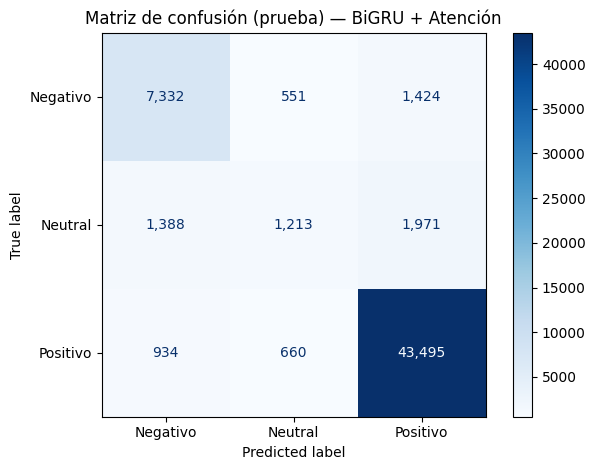

In [10]:
PROBS_TEST = PRED_TEST = None
cm_registrada = np.array(RESULTADOS_U3['matriz_confusion_test'])

if RUTA_DATOS is not None:
    with np.load(RUTA_DATOS, allow_pickle=False) as z:
        faltantes = {'X_test', 'y_test'} - set(z.files)
        if faltantes:
            raise KeyError(f"A {RUTA_DATOS.name} le faltan claves: {faltantes}")
        X_test = z['X_test'].astype(np.int32)
        y_test = z['y_test'].ravel().astype(np.int32)

    assert X_test.ndim == 2 and X_test.shape[1] == MAX_LEN
    assert len(X_test) == len(y_test)

    inicio = time.perf_counter()
    PROBS_TEST = modelo.predict(X_test, batch_size=512, verbose=0)
    TIEMPO_PRED_TEST = time.perf_counter() - inicio
    PRED_TEST = PROBS_TEST.argmax(axis=1)

    metricas_recalculadas = {
        'Accuracy': accuracy_score(y_test, PRED_TEST),
        'F1-macro': f1_score(y_test, PRED_TEST, average='macro', zero_division=0),
        'Precision macro': precision_score(y_test, PRED_TEST, average='macro', zero_division=0),
        'Recall macro': recall_score(y_test, PRED_TEST, average='macro', zero_division=0),
    }
    print(f'Métricas recalculadas sobre {len(y_test):,} reseñas de prueba:')
    display(pd.DataFrame([metricas_recalculadas]).round(4))
    print(classification_report(y_test, PRED_TEST, target_names=NOMBRES_CLASE, digits=4, zero_division=0))

    cm_actual = confusion_matrix(y_test, PRED_TEST, labels=list(range(len(NOMBRES_CLASE))))
    dif_cm = int(np.abs(cm_actual - cm_registrada).max())
    COINCIDE_F1 = abs(metricas_recalculadas['F1-macro'] - metricas_hist['f1_macro']) < 1e-3
    COINCIDE_CM = dif_cm <= 5  # tolerancia por diferencias numéricas entre CPU y GPU
    print('Verificación de reproducibilidad')
    print(f"  F1-macro recalculado {metricas_recalculadas['F1-macro']:.4f} vs registrado {metricas_hist['f1_macro']:.4f}:",
          'coincide' if COINCIDE_F1 else 'NO coincide')
    print(f'  Matriz de confusión: diferencia máxima por celda = {dif_cm} reseñas ->',
          'coincide' if COINCIDE_CM else 'NO coincide')

    disp = ConfusionMatrixDisplay(confusion_matrix=cm_actual, display_labels=NOMBRES_CLASE)
    disp.plot(cmap='Blues', values_format=',')
    plt.title('Matriz de confusión (prueba) — BiGRU + Atención')
    plt.tight_layout()
    plt.show()
else:
    cm_actual = cm_registrada
    print('No se encontró datos_lab2.npz: se usa la matriz de confusión registrada.')
    print('Las secciones 10 y 11 necesitan ese archivo para calcularse.')

## 9. Comparación con la línea base y criterio de éxito

La tabla reúne las métricas registradas en las unidades 2 y 3. Los tiempos por época **no son comparables directamente**: la GRU se entrenó con GPU y la BiGRU sin GPU. La variante BiGRU sin atención (F1-macro de prueba 0,6828) se reporta en el informe de la Unidad 4; su archivo de resultados no forma parte de este paquete, por lo que no se recalcula aquí.

In [11]:
def hardware(resultados):
    if not resultados:
        return 'N/D'
    return 'GPU' if resultados['entorno'].get('gpu_disponible') else 'CPU'


base = RESULTADOS_U3['comparacion_con_base']
row_gru = base['GRU (Unidad 2 - base)']
row_att = base['BiGRU + Atencion (Unidad 3)']
exp_cw = RESULTADOS_U3.get('experimento_class_weight', {})

comparacion = pd.DataFrame([
    {'Modelo': 'GRU base (U2)', 'F1 validación': row_gru['F1-macro validacion'],
     'F1 prueba': row_gru['F1-macro test'], 'Accuracy prueba': row_gru['Accuracy test'],
     'Parámetros': int(row_gru['Parametros']), 'Tiempo/época (s)': row_gru['Tiempo/epoca (s)'],
     'Hardware': hardware(RESULTADOS_U2)},
    {'Modelo': 'BiGRU + Atención (U3)', 'F1 validación': row_att['F1-macro validacion'],
     'F1 prueba': row_att['F1-macro test'], 'Accuracy prueba': row_att['Accuracy test'],
     'Parámetros': int(row_att['Parametros']), 'Tiempo/época (s)': row_att['Tiempo/epoca (s)'],
     'Hardware': hardware(RESULTADOS_U3)},
    {'Modelo': 'BiGRU + Atención + class_weight (U3)', 'F1 validación': np.nan,
     'F1 prueba': exp_cw.get('test_f1_macro', np.nan), 'Accuracy prueba': exp_cw.get('test_accuracy', np.nan),
     'Parámetros': int(row_att['Parametros']), 'Tiempo/época (s)': np.nan,
     'Hardware': hardware(RESULTADOS_U3)},
])
display(comparacion.round(4))


def metricas_por_clase(cm):
    cm = np.asarray(cm, dtype=float)
    precision = np.diag(cm) / cm.sum(axis=0)
    recall = np.diag(cm) / cm.sum(axis=1)
    f1 = 2 * precision * recall / (precision + recall)
    return precision, recall, f1


_, rec_att, f1_att = metricas_por_clase(cm_actual)
_, rec_gru, f1_gru = metricas_por_clase(RESULTADOS_U2['matriz_confusion_test'] if RESULTADOS_U2 else np.full((3, 3), np.nan))
por_clase = pd.DataFrame({
    'F1 GRU (U2)': f1_gru, 'F1 BiGRU + Atención': f1_att, 'Diferencia F1': f1_att - f1_gru,
    'Recall GRU (U2)': rec_gru, 'Recall BiGRU + Atención': rec_att,
}, index=NOMBRES_CLASE)
display(por_clase.round(4))

CRITERIO_VALIDACION = row_att['F1-macro validacion'] > row_gru['F1-macro validacion']
CRITERIO_CLASES = (bool(np.all(por_clase['Diferencia F1'] >= -0.01))  # ninguna clase pierde más de 1 punto
                   if RESULTADOS_U2 else None)
print('Criterio de éxito (Actividad 1)')
print(f"  1. Supera a la GRU en F1-macro de validación ({row_att['F1-macro validacion']:.4f} vs "
      f"{row_gru['F1-macro validacion']:.4f}):", 'CUMPLE' if CRITERIO_VALIDACION else 'NO CUMPLE')
print('  2. Sin deterioro en ninguna clase (pérdida de F1 menor a 0,01):',
      {True: 'CUMPLE', False: 'NO CUMPLE', None: 'N/D (falta resultados_lab2.json)'}[CRITERIO_CLASES])

,Modelo,F1 validación,F1 prueba,Accuracy prueba,Parámetros,Tiempo/época (s),Hardware
0,GRU base (U2),0.6911,0.6776,0.8754,2597699,34.8,GPU
1,BiGRU + Atención (U3),0.7011,0.6886,0.8825,2651395,2421.7,CPU
2,BiGRU + Atención + class_weight (U3),NaN,0.6743,0.8126,2651395,NaN,CPU


,F1 GRU (U2),F1 BiGRU + Atención,Diferencia F1,Recall GRU (U2),Recall BiGRU + Atención
Negativo,0.7548,0.7734,0.0186,0.7492,0.7878
Neutral,0.3371,0.3468,0.0096,0.2622,0.2653
Positivo,0.9410,0.9458,0.0048,0.9636,0.9646


Criterio de éxito (Actividad 1)
  1. Supera a la GRU en F1-macro de validación (0.7011 vs 0.6911): CUMPLE
  2. Sin deterioro en ninguna clase (pérdida de F1 menor a 0,01): CUMPLE


## 10. Análisis de errores

Se analizan tres aspectos: qué clases se confunden más, cómo cambia el desempeño con la longitud de la reseña y ejemplos reales de error. Las reseñas se reconstruyen a partir de los índices del vocabulario, por eso aparecen en minúsculas, sin puntuación y con `<OOV>` en las palabras desconocidas.

In [12]:
POR_LONGITUD = None
if PRED_TEST is not None:
    confianza = PROBS_TEST.max(axis=1)
    longitudes = (X_test != PAD_IDX).sum(axis=1)

    # 1) Confusiones más frecuentes
    pares = [{'Real': NOMBRES_CLASE[i], 'Predicho': NOMBRES_CLASE[j], 'Reseñas': int(cm_actual[i, j]),
              '% de la clase real': cm_actual[i, j] / cm_actual[i].sum()}
             for i in range(3) for j in range(3) if i != j]
    display(pd.DataFrame(pares).sort_values('Reseñas', ascending=False).reset_index(drop=True).round(3))

    # 2) Desempeño según la longitud (200 = reseña truncada)
    filas = []
    for a, b in [(1, 20), (21, 50), (51, 100), (101, 199), (200, 200)]:
        m = (longitudes >= a) & (longitudes <= b)
        filas.append({'Palabras': f'{a}-{b}' if a != b else f'{a} (truncadas)', 'Reseñas': int(m.sum()),
                      '% del total': m.mean(), 'Accuracy': accuracy_score(y_test[m], PRED_TEST[m]),
                      'F1-macro': f1_score(y_test[m], PRED_TEST[m], average='macro', zero_division=0)})
    POR_LONGITUD = pd.DataFrame(filas)
    display(POR_LONGITUD.round(3))

    # 3) Ejemplos reales de error
    rng = np.random.default_rng(SEED)

    def decodificar(fila):
        return ' '.join(INDICE_A_PALABRA.get(int(i), '<OOV>') for i in fila if i != PAD_IDX)

    def muestras(real, predicho, n, tipo, alta_confianza=False):
        idx = np.where((y_test == real) & (PRED_TEST == predicho) & (longitudes <= 60))[0]
        if alta_confianza:
            idx = idx[np.argsort(-confianza[idx])][:100]
        elegidos = rng.choice(idx, size=min(n, len(idx)), replace=False)
        return [{'Tipo de error': tipo, 'Real': NOMBRES_CLASE[real], 'Predicho': NOMBRES_CLASE[predicho],
                 'Confianza': round(float(confianza[i]), 3), 'Reseña (reconstruida)': decodificar(X_test[i])}
                for i in elegidos]

    ejemplos_error = (muestras(1, 2, 3, 'Neutral leída como positiva')
                      + muestras(1, 0, 2, 'Neutral leída como negativa')
                      + muestras(0, 2, 3, 'Negativa con alta confianza en Positivo', alta_confianza=True))
    display(pd.DataFrame(ejemplos_error))
else:
    print('Se necesita datos_lab2.npz para el análisis de errores.')

,Real,Predicho,Reseñas,% de la clase real
0,Neutral,Positivo,1971,0.431
1,Negativo,Positivo,1424,0.153
2,Neutral,Negativo,1388,0.304
3,Positivo,Negativo,934,0.021
4,Positivo,Neutral,660,0.015
5,Negativo,Neutral,551,0.059


,Palabras,Reseñas,% del total,Accuracy,F1-macro
0,1-20,1088,0.018,0.908,0.675
1,21-50,26000,0.441,0.906,0.699
2,51-100,18386,0.312,0.881,0.698
3,101-199,10070,0.171,0.858,0.691
4,200 (truncadas),3424,0.058,0.776,0.572


,Tipo de error,Real,Predicho,Confianza,Reseña (reconstruida)
0,Neutral leída como positiva,Neutral,Positivo,0.584,this tea is a new flavor of black tea by tazo it's better than some other brands but not even close to being as good as their old flavor of black tea with c...
1,Neutral leída como positiva,Neutral,Positivo,0.579,i didn't realize there were different types of cat grass grows well but my cat who loves <OOV> brand of cat grass doesn't really like this product
2,Neutral leída como positiva,Neutral,Positivo,0.471,i love these bars i would actually give them a 5 stars however the ones i got from amazon they were almost half baked and they stick to your teeth i am not ...
3,Neutral leída como negativa,Neutral,Negativo,0.717,been feeding this food to my greyhound for 10 years was paying 40 99 from amazon now after nearly a 25 price increase i am forced to shop elsewhere sorry am...
4,Neutral leída como negativa,Neutral,Negativo,0.950,the package was nicely packaged and arrived in a timely matter maybe it's just me but these are horrible tasting i about choked when i opened the bag and sm...
5,Negativa con alta confianza en Positivo,Negativo,Positivo,0.992,i guess the <OOV> all my own for thinking that they could get me chocolate through the mail without it all being melted but that was the case two packs of t...
6,Negativa con alta confianza en Positivo,Negativo,Positivo,0.995,buy the 3 pack with subscribe and save different item i have used this product a long time and it is consistent i also started ordering it because of hotels...
7,Negativa con alta confianza en Positivo,Negativo,Positivo,0.971,our family has liked every other flavored we have tried bbq is the best we like sweet potatoes so we assumed would like these pop chips i was wrong no one i...


**Lectura:** el error más frecuente es leer reseñas neutrales como positivas. Varias de ellas tienen texto claramente favorable pese a sus 3 estrellas, lo que indica **ruido en la etiqueta** derivada de `Score`. Las reseñas truncadas en 200 palabras tienen el peor desempeño porque se pierde el final, donde suele estar la conclusión. Los errores de alta confianza incluyen sarcasmo y quejas redactadas con palabras amables.

## 10.1 Vocabulario y palabras desconocidas

El modelo solo conoce las **20.000 palabras más frecuentes del conjunto de entrenamiento** (más `<PAD>` y `<OOV>`, 20.002 índices). Cualquier otra palabra se convierte en `<OOV>`: el modelo sabe que ahí había *algo*, pero no qué. Como la partición es cronológica, comparar la tasa de `<OOV>` entre entrenamiento, validación y prueba muestra si el lenguaje cambia con el tiempo.

In [13]:
VOCABULARIO = {'tamano_vocabulario': VOCAB_SIZE - 2, 'tamano_indice': VOCAB_SIZE}
capa_embedding = next(c for c in modelo.layers if isinstance(c, keras.layers.Embedding))
params_embedding = int(np.prod(capa_embedding.embeddings.shape))
VOCABULARIO['parametros_embedding'] = params_embedding
VOCABULARIO['parametros_modelo'] = int(modelo.count_params())
print(f'Palabras conocidas: {VOCAB_SIZE - 2:,} (índice total {VOCAB_SIZE:,} con <PAD> y <OOV>)')
print(f'Parámetros del embedding: {params_embedding:,} de {modelo.count_params():,} '
      f'({params_embedding / modelo.count_params():.0%} del modelo)')
print('Últimas palabras que alcanzaron a entrar (las menos frecuentes):',
      [INDICE_A_PALABRA[i] for i in range(VOCAB_SIZE - 6, VOCAB_SIZE)])

# 1) Tasa de <OOV> por partición (orden cronológico)
if RUTA_DATOS is not None:
    filas = []
    with np.load(RUTA_DATOS, allow_pickle=False) as z:
        for parte in ['train', 'val', 'test']:
            X = z[f'X_{parte}']
            reales = (X != PAD_IDX).sum()
            desconocidas = (X == OOV_IDX)
            filas.append({'Partición': parte, 'Tokens': int(reales),
                          '% tokens <OOV>': desconocidas.sum() / reales,
                          '% reseñas con al menos un <OOV>': desconocidas.any(axis=1).mean()})
            del X, desconocidas
    TABLA_OOV = pd.DataFrame(filas)
    VOCABULARIO['oov_por_particion'] = TABLA_OOV.to_dict('records')
    display(TABLA_OOV.round(4))

# 2) Desempeño en prueba según la proporción de palabras desconocidas
if PRED_TEST is not None:
    proporcion_oov = (X_test == OOV_IDX).sum(axis=1) / np.maximum(1, (X_test != PAD_IDX).sum(axis=1))
    filas = []
    for etiqueta, m in [('0 %', proporcion_oov == 0),
                        ('0–2 %', (proporcion_oov > 0) & (proporcion_oov <= 0.02)),
                        ('2–5 %', (proporcion_oov > 0.02) & (proporcion_oov <= 0.05)),
                        ('5–10 %', (proporcion_oov > 0.05) & (proporcion_oov <= 0.10)),
                        ('> 10 %', proporcion_oov > 0.10)]:
        filas.append({'Palabras <OOV>': etiqueta, 'Reseñas': int(m.sum()),
                      'Accuracy': accuracy_score(y_test[m], PRED_TEST[m]),
                      'F1-macro': f1_score(y_test[m], PRED_TEST[m], average='macro', zero_division=0)})
    TABLA_OOV_DESEMPENO = pd.DataFrame(filas)
    VOCABULARIO['desempeno_por_oov'] = TABLA_OOV_DESEMPENO.to_dict('records')
    display(TABLA_OOV_DESEMPENO.round(3))

# 3) Términos que se popularizaron después del periodo de los datos (hasta 2012)
recientes = ['keto', 'covid', 'pandemic', 'airfryer', 'oatmilk', 'monkfruit', 'collagen',
             'tiktok', 'instagram', 'vegan', 'kombucha', 'sriracha', 'quinoa', 'stevia']
VOCABULARIO['terminos_recientes_oov'] = [p for p in recientes if p not in word_index]
display(pd.DataFrame({'Palabra': recientes,
                      '¿En el vocabulario?': ['Sí' if p in word_index else 'No → <OOV>' for p in recientes]}).T)

# 4) Reseñas actuales: qué ve el modelo y qué predice
ejemplos_actuales = {
    'Producto nuevo, opinión clara': ('The keto bread was a total flop', 'Negativo'),
    'Jerga nueva como palabra clave': ('Honestly this snack is bussin, no cap', 'Positivo'),
    'Palabra conocida con significado nuevo': ('This keto snack is mid', 'Neutral'),
}
filas = []
for caso, (texto, esperado) in ejemplos_actuales.items():
    r = predecir_sentimiento(texto)
    filas.append({'Caso': caso, 'Reseña': texto,
                  'Lo que ve el modelo': ' '.join(t if t in word_index else '<OOV>' for t in r['tokens_utilizados']),
                  'Esperado': esperado, 'Predicho': r['sentimiento_predicho'],
                  'Probabilidad máxima': round(r['probabilidad_maxima'], 3)})
display(pd.DataFrame(filas))

Palabras conocidas: 20,000 (índice total 20,002 con <PAD> y <OOV>)
Parámetros del embedding: 2,560,256 de 2,651,395 (97% del modelo)
Últimas palabras que alcanzaron a entrar (las menos frecuentes): ['sacrilege', 'sweettarts', 'casting', 'vinegrette', 'scaring', 'catchup']


,Partición,Tokens,% tokens <OOV>,% reseñas con al menos un <OOV>
0,train,20070525,0.0089,0.3443
1,val,4583129,0.0098,0.3812
2,test,4272285,0.0102,0.3770


,Palabras <OOV>,Reseñas,Accuracy,F1-macro
0,0 %,36739,0.894,0.702
1,0–2 %,11301,0.853,0.671
2,2–5 %,9169,0.875,0.665
3,5–10 %,1560,0.871,0.639
4,> 10 %,199,0.859,0.608


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
Palabra,keto,covid,pandemic,airfryer,oatmilk,monkfruit,collagen,tiktok,instagram,vegan,kombucha,sriracha,quinoa,stevia
¿En el vocabulario?,No → <OOV>,No → <OOV>,No → <OOV>,No → <OOV>,No → <OOV>,No → <OOV>,No → <OOV>,No → <OOV>,No → <OOV>,Sí,Sí,Sí,Sí,Sí


,Caso,Reseña,Lo que ve el modelo,Esperado,Predicho,Probabilidad máxima
0,"Producto nuevo, opinión clara",The keto bread was a total flop,the <OOV> bread was a total flop,Negativo,Negativo,0.983
1,Jerga nueva como palabra clave,"Honestly this snack is bussin, no cap",honestly this snack is <OOV> no cap,Positivo,Negativo,0.755
2,Palabra conocida con significado nuevo,This keto snack is mid,this <OOV> snack is mid,Neutral,Positivo,0.738


**Lectura:** el vocabulario cubre alrededor del 99 % de los tokens. La tasa de `<OOV>` sube levemente de entrenamiento (0,89 %) a prueba (1,02 %), que corresponde al periodo más reciente; dentro de los años del dataset (hasta 2012) el cambio es pequeño, pero muestra la tendencia que se acentuará con reseñas posteriores. El F1-macro baja a medida que una reseña tiene más palabras desconocidas. La relación está parcialmente mezclada con la longitud (las reseñas largas acumulan más palabras raras). Términos actuales como *keto*, *covid* o *airfryer* no existen para el modelo. Si el sentimiento está en otras palabras, acierta igual (*keto bread was a total flop*); si la palabra clave es nueva (*bussin*), el modelo adivina a partir del resto y puede equivocarse con confianza. Además, hay palabras conocidas cuyo significado cambió (*mid* hoy significa "mediocre"), algo que la tasa de `<OOV>` no detecta. Con lenguaje que siga cambiando, el modelo necesitará **monitorear la tasa de `<OOV>`** y **reconstruir el vocabulario** o usar tokenización por subpalabras.

## 11. Umbral de revisión humana

Si la probabilidad máxima es menor que un umbral, la reseña se envía a una persona. Un umbral más alto envía más reseñas a revisión y deja en el grupo automático solo las predicciones más seguras. Se elige **0,60** porque mantiene automático cerca del 90 % del volumen y eleva el accuracy de ese grupo por encima de 92 %.

,Umbral,% automático,Accuracy automática,F1-macro automático,% de errores enviados a revisión,Reseñas a revisar
0,0.40,0.992,0.887,0.692,0.043,458
1,0.45,0.977,0.894,0.696,0.117,1342
2,0.50,0.954,0.905,0.701,0.225,2721
3,0.55,0.928,0.915,0.703,0.330,4220
4,0.60,0.903,0.926,0.707,0.432,5717
5,0.65,0.879,0.935,0.706,0.512,7131
6,0.70,0.854,0.943,0.705,0.585,8613
7,0.75,0.827,0.951,0.705,0.654,10174
8,0.80,0.796,0.959,0.709,0.724,12004
9,0.85,0.760,0.968,0.716,0.790,14145


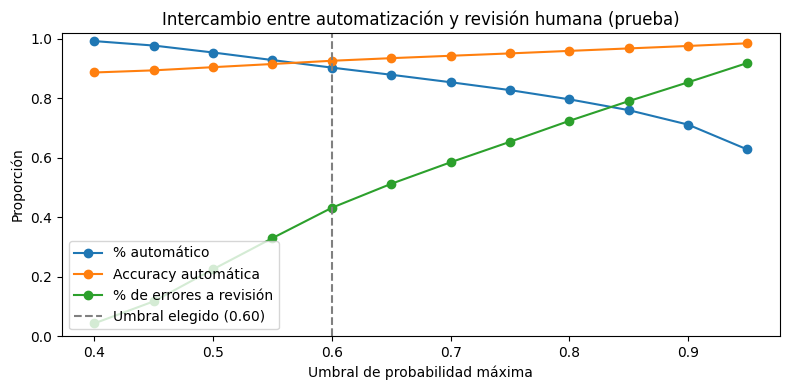

Con umbral 0.60: 90.3% automático, accuracy automática 92.6%, 43.2% de los errores llega a revisión.


In [14]:
TABLA_UMBRAL = None
if PRED_TEST is not None:
    errores = PRED_TEST != y_test
    filas = []
    for u in np.round(np.arange(0.40, 0.96, 0.05), 2):
        auto = confianza >= u
        filas.append({'Umbral': u, '% automático': auto.mean(),
                      'Accuracy automática': accuracy_score(y_test[auto], PRED_TEST[auto]),
                      'F1-macro automático': f1_score(y_test[auto], PRED_TEST[auto], average='macro', zero_division=0),
                      '% de errores enviados a revisión': (errores & ~auto).sum() / errores.sum(),
                      'Reseñas a revisar': int((~auto).sum())})
    TABLA_UMBRAL = pd.DataFrame(filas)
    display(TABLA_UMBRAL.round(3))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(TABLA_UMBRAL['Umbral'], TABLA_UMBRAL['% automático'], marker='o', label='% automático')
    ax.plot(TABLA_UMBRAL['Umbral'], TABLA_UMBRAL['Accuracy automática'], marker='o', label='Accuracy automática')
    ax.plot(TABLA_UMBRAL['Umbral'], TABLA_UMBRAL['% de errores enviados a revisión'], marker='o', label='% de errores a revisión')
    ax.axvline(UMBRAL_REVISION, linestyle='--', color='gray', label=f'Umbral elegido ({UMBRAL_REVISION:.2f})')
    ax.set_xlabel('Umbral de probabilidad máxima')
    ax.set_ylabel('Proporción')
    ax.set_ylim(0, 1.02)
    ax.set_title('Intercambio entre automatización y revisión humana (prueba)')
    ax.legend(loc='lower left')
    plt.tight_layout()
    plt.show()

    elegido = TABLA_UMBRAL.loc[np.isclose(TABLA_UMBRAL['Umbral'], UMBRAL_REVISION)].iloc[0]
    print(f"Con umbral {UMBRAL_REVISION:.2f}: {elegido['% automático']:.1%} automático, "
          f"accuracy automática {elegido['Accuracy automática']:.1%}, "
          f"{elegido['% de errores enviados a revisión']:.1%} de los errores llega a revisión.")
else:
    print('Se necesita datos_lab2.npz para calcular la curva del umbral.')

## 11.1 Ajuste por clase para mejorar Neutral

El modelo tiende a elegir Positivo, la clase mayoritaria. Sin reentrenar, cada probabilidad se puede multiplicar por un peso antes de elegir la clase: un peso mayor en Neutral le da más oportunidades de ganar. Los pesos se buscan **solo en validación** y se aplican una única vez a prueba, para no ajustar nada con el conjunto de prueba. Positivo queda fijo en 1.

In [15]:
PESOS_CLASE = np.ones(len(NOMBRES_CLASE))
TABLA_AJUSTE = None
if PRED_TEST is not None:
    with np.load(RUTA_DATOS, allow_pickle=False) as z:
        X_val = z['X_val'].astype(np.int32)
        y_val = z['y_val'].ravel().astype(np.int32)
    PROBS_VAL = modelo.predict(X_val, batch_size=512, verbose=0)
    PRED_VAL = PROBS_VAL.argmax(axis=1)

    def f1_macro_rapido(y, pred, k=len(NOMBRES_CLASE)):
        cm = np.bincount(y * k + pred, minlength=k * k).reshape(k, k)
        return np.mean(2 * np.diag(cm) / np.maximum(1, cm.sum(axis=0) + cm.sum(axis=1)))

    # Búsqueda en validación: pesos de Negativo y Neutral entre 0,6 y 3,0
    mejor_f1 = f1_macro_rapido(y_val, PRED_VAL)
    rejilla = np.round(np.arange(0.6, 3.01, 0.1), 1)
    for w_neg in rejilla:
        for w_neu in rejilla:
            pesos = np.array([w_neg, w_neu, 1.0])
            f1 = f1_macro_rapido(y_val, (PROBS_VAL * pesos).argmax(axis=1))
            if f1 > mejor_f1 + 1e-9:
                mejor_f1, PESOS_CLASE = f1, pesos
    print('Pesos elegidos en validación:', dict(zip(NOMBRES_CLASE, PESOS_CLASE.round(2))))

    PRED_VAL_AJUSTE = (PROBS_VAL * PESOS_CLASE).argmax(axis=1)
    PRED_TEST_AJUSTE = (PROBS_TEST * PESOS_CLASE).argmax(axis=1)
    filas = []
    for conjunto, y, sin_ajuste, con_ajuste in [('Validación', y_val, PRED_VAL, PRED_VAL_AJUSTE),
                                                ('Prueba', y_test, PRED_TEST, PRED_TEST_AJUSTE)]:
        for variante, pred in [('Sin ajuste', sin_ajuste), ('Con ajuste por clase', con_ajuste)]:
            f1_clase = f1_score(y, pred, average=None, zero_division=0)
            filas.append({'Conjunto': conjunto, 'Variante': variante,
                          'Accuracy': accuracy_score(y, pred),
                          'F1-macro': f1_score(y, pred, average='macro', zero_division=0),
                          'F1 Negativo': f1_clase[0], 'F1 Neutral': f1_clase[1], 'F1 Positivo': f1_clase[2],
                          'Recall Neutral': recall_score(y, pred, average=None, zero_division=0)[1]})
    TABLA_AJUSTE = pd.DataFrame(filas)
    display(TABLA_AJUSTE.round(4))

    print('Matriz de confusión en prueba con ajuste (filas = real, columnas = predicho):')
    display(pd.DataFrame(confusion_matrix(y_test, PRED_TEST_AJUSTE), index=NOMBRES_CLASE, columns=NOMBRES_CLASE))

    # Combinación con el umbral: revisión si la probabilidad original de la clase elegida es baja
    auto = PROBS_TEST[np.arange(len(y_test)), PRED_TEST_AJUSTE] >= UMBRAL_REVISION
    print(f'Con umbral {UMBRAL_REVISION:.2f} y ajuste: {auto.mean():.1%} automático, accuracy automática '
          f'{accuracy_score(y_test[auto], PRED_TEST_AJUSTE[auto]):.1%}, F1-macro automático '
          f"{f1_score(y_test[auto], PRED_TEST_AJUSTE[auto], average='macro'):.4f}")
else:
    print('Se necesita datos_lab2.npz para buscar el ajuste por clase.')

Pesos elegidos en validación: {'Negativo': np.float64(1.2), 'Neutral': np.float64(2.0), 'Positivo': np.float64(1.0)}


,Conjunto,Variante,Accuracy,F1-macro,F1 Negativo,F1 Neutral,F1 Positivo,Recall Neutral
0,Validación,Sin ajuste,0.8785,0.7011,0.7783,0.3828,0.9423,0.3035
1,Validación,Con ajuste por clase,0.8695,0.7192,0.7734,0.4455,0.9387,0.4707
2,Prueba,Sin ajuste,0.8825,0.6886,0.7734,0.3468,0.9458,0.2653
3,Prueba,Con ajuste por clase,0.8743,0.7076,0.7647,0.4143,0.9437,0.4210


Matriz de confusión en prueba con ajuste (filas = real, columnas = predicho):


,Negativo,Neutral,Positivo
Negativo,6965,1206,1136
Neutral,1111,1925,1536
Positivo,833,1590,42666


Con umbral 0.60 y ajuste: 90.0% automático, accuracy automática 92.7%, F1-macro automático 0.7084


**Lectura:** con un ajuste que no requiere reentrenar, el F1-macro de prueba sube más de lo que ganó la BiGRU frente a la GRU (+0,011), y el recall de Neutral pasa de una de cada cuatro reseñas a cuatro de cada diez. El costo es una pequeña baja en accuracy (de 0,8825 a 0,8743) y casi un punto menos de F1 en Negativo, porque algunas reseñas positivas y negativas pasan a Neutral. Como los pesos se eligieron en validación, el resultado de prueba no está sobreajustado. Para usarlo en producción basta con `predecir_sentimiento(texto, pesos=PESOS_CLASE)`.

## 12. Costo computacional y latencia

El plan de la Actividad 1 pide registrar hardware, tiempo de entrenamiento y latencia de predicción. Los tiempos de entrenamiento provienen de los archivos de resultados; la latencia se mide en este entorno.

In [16]:
secuencia_ejemplo = texto_a_secuencia(reseñas_demo['Opinión mixta'])[0][np.newaxis, :]
for _ in range(5):  # calentamiento
    inferir(secuencia_ejemplo)
tiempos_ms = []
for _ in range(50):
    inicio = time.perf_counter()
    inferir(secuencia_ejemplo).numpy()
    tiempos_ms.append((time.perf_counter() - inicio) * 1000)

LATENCIA = {'mediana_ms': float(np.median(tiempos_ms)), 'p95_ms': float(np.percentile(tiempos_ms, 95))}
if PRED_TEST is not None:
    LATENCIA['reseñas_por_segundo_en_lote'] = float(len(X_test) / TIEMPO_PRED_TEST)

costos = pd.DataFrame([
    {'Modelo': 'GRU base (U2)', 'Entrenamiento (min)': RESULTADOS_U2['tiempo_entrenamiento_min'] if RESULTADOS_U2 else np.nan,
     'Hardware de entrenamiento': hardware(RESULTADOS_U2)},
    {'Modelo': 'BiGRU + Atención (U3)', 'Entrenamiento (min)': RESULTADOS_U3['tiempo_entrenamiento_min'],
     'Hardware de entrenamiento': hardware(RESULTADOS_U3)},
])
display(costos)
print(f"Hardware de esta ejecución: {'GPU' if ENTORNO['gpu_disponible'] else 'CPU'} ({ENTORNO['procesador']})")
print(f"Latencia por reseña: mediana {LATENCIA['mediana_ms']:.1f} ms, percentil 95 {LATENCIA['p95_ms']:.1f} ms")
if 'reseñas_por_segundo_en_lote' in LATENCIA:
    print(f"Procesamiento en lote: {LATENCIA['reseñas_por_segundo_en_lote']:,.0f} reseñas por segundo")

,Modelo,Entrenamiento (min),Hardware de entrenamiento
0,GRU base (U2),2.90,GPU
1,BiGRU + Atención (U3),161.45,CPU


Hardware de esta ejecución: CPU (x86_64)
Latencia por reseña: mediana 14.1 ms, percentil 95 18.0 ms
Procesamiento en lote: 1,017 reseñas por segundo


## 13. Registro de resultados de esta ejecución

Se guarda `resultados_u5.json` junto al modelo, con el entorno, las métricas recalculadas, la verificación de reproducibilidad, el umbral y la latencia. Este archivo es la evidencia trazable de la ejecución final.

In [17]:
def a_json(valor):
    if hasattr(valor, 'tolist'):  # arreglos y escalares de NumPy
        return valor.tolist()
    return str(valor)


RESULTADOS_U5 = {
    'entorno': ENTORNO,
    'umbral_revision': UMBRAL_REVISION,
    'latencia': LATENCIA,
    'criterio_exito': {'supera_gru_en_validacion': CRITERIO_VALIDACION, 'sin_deterioro_por_clase': CRITERIO_CLASES},
    'f1_por_clase': por_clase.to_dict(),
    'demo': df_demo.to_dict('records'),
    'vocabulario': VOCABULARIO,
    'ajuste_por_clase': {'pesos': dict(zip(NOMBRES_CLASE, PESOS_CLASE)),
                         'comparacion': TABLA_AJUSTE.to_dict('records') if TABLA_AJUSTE is not None else None},
}
if PRED_TEST is not None:
    RESULTADOS_U5.update({
        'metricas_recalculadas_test': metricas_recalculadas,
        'matriz_confusion_test': cm_actual,
        'coincide_con_registro': {'f1_macro': COINCIDE_F1, 'matriz_confusion': COINCIDE_CM},
        'por_longitud': POR_LONGITUD.to_dict('records'),
        'curva_umbral': TABLA_UMBRAL.to_dict('records'),
    })

ruta_salida = CARPETA_SALIDA / 'resultados_u5.json'
with open(ruta_salida, 'w', encoding='utf-8') as f:
    json.dump(RESULTADOS_U5, f, ensure_ascii=False, indent=2, default=a_json)
print('Resultados guardados en', ruta_salida.name)

Resultados guardados en resultados_u5.json


## 14. Riesgos, límites y controles

- **Desbalance:** F1-macro y métricas por clase acompañan a accuracy; Neutral debe vigilarse explícitamente (F1 ≈ 0,35).
- **Ruido en la etiqueta:** la clase se derivó de `Score`; algunas reseñas de 3 estrellas tienen texto claramente positivo. Parte del error en Neutral no es atribuible al modelo.
- **Truncamiento:** solo se leen las primeras 200 palabras; las reseñas más largas pierden la conclusión y tienen el peor desempeño.
- **Sarcasmo e ironía:** pueden producir errores con alta confianza que el umbral no atrapa.
- **Preprocesamiento:** se reutilizan la limpieza, la expresión regular de tokens, el vocabulario, `<OOV>`, `MAX_LEN=200` y el padding posterior de la Unidad 1.
- **Data leakage:** `Score` no es predictor; el vocabulario no se vuelve a ajustar; la selección se hizo con validación. El conjunto de prueba ya se usó en unidades previas, por lo que no es una evaluación completamente independiente.
- **Vocabulario fijo y cambios de dominio:** el modelo solo conoce 20.000 palabras del periodo de entrenamiento; la tasa de `<OOV>` ya crece en prueba (sección 10.1). Conviene monitorearla junto con la distribución de predicciones.
- **Probabilidades:** son estimaciones del modelo, no garantías. Las reseñas bajo el umbral se envían a revisión humana.
- **Despliegue:** este notebook es un prototipo académico. Antes de producción se requieren pruebas de carga, monitoreo, controles de privacidad y medición de rendimiento en el entorno objetivo.

## 15. Trabajo en equipo y trazabilidad

Integrantes: Kinan El Halabi Jaber, Joel Montenegro González y Valentina Ramírez Puerto. Los roles se definieron en el plan de la Actividad 1.

| Rol | Responsable | Tareas | Evidencia en el paquete |
|---|---|---|---|
| Integración técnica | *Joel Montenegro* | Organizar artefactos, función de inferencia, ejecución desde cero en Colab | Secciones 2–6, `resultados_u5.json` |
| Evaluación y calidad | *Valentina Ramirez* | Verificación de métricas, comparación con la GRU, análisis de errores, umbral | Secciones 8–12 |
| Documentación y comunicación | *Kinan El Halabi* | Informe técnico, resumen ejecutivo, presentación | Resumen ejecutivo, informe y presentación |

| Unidad | Producto | Artefacto |
|---|---|---|
| U1 | Limpieza, vocabulario, secuencias y partición cronológica | `word_index.json`, `parametros_pipeline.json`, `datos_lab2.npz` |
| U2 | GRU base | `resultados_lab2.json` |
| U3 | BiGRU + Atención y experimento con `class_weight` | `modelo_bigru_atencion_lab3.keras`, `resultados_lab3.json` |
| U4 | Evaluación comparativa y control de fuga | Informe de la Unidad 4 |
| U5 | Integración, verificación y propuesta de uso | Este notebook, `resultados_u5.json` |

## 16. Conclusiones y mejoras futuras

El prototipo integra el modelo BiGRU + Atención con el preprocesamiento original y clasifica reseñas nuevas sin reentrenar. La evaluación recalculada coincide con la corrida registrada de la Unidad 3 (F1-macro de prueba 0,6886, accuracy 0,8825), lo que confirma la reproducibilidad del resultado. El modelo cumple el criterio de éxito: supera a la GRU base en F1-macro de validación (0,7011 frente a 0,6911) y mejora el F1 de las tres clases, aunque la ganancia es de alrededor de un punto y su entrenamiento es mucho más costoso.

La recomendación es usar BiGRU + Atención con un **umbral de revisión humana de 0,60**: el sistema resuelve automáticamente alrededor del 90 % de las reseñas con un accuracy cercano al 93 % y envía a revisión casi la mitad de los errores. La GRU se conserva como referencia de bajo costo.

El **ajuste por clase** de la sección 11.1, elegido en validación, eleva el F1-macro de prueba de 0,6886 a 0,7076 y el recall de Neutral de 0,27 a 0,42 sin reentrenar. Es una mejora mayor que la obtenida al pasar de GRU a BiGRU + Atención, por lo que se recomienda adoptarlo si el objetivo es detectar mejor las reseñas neutrales; si importa más el acierto global, se puede omitir.

**Mejoras futuras propuestas**

1. **Clase Neutral:** además del ajuste por clase ya aplicado, probar *focal loss* al reentrenar y seguir el F1 de Neutral como métrica propia.
2. **Truncamiento:** comparar en validación `truncating='pre'` o `MAX_LEN=300`, ya que las reseñas truncadas tienen el peor desempeño.
3. **Calidad de etiquetas:** revisar manualmente una muestra de errores Neutral↔Positivo para estimar cuánto se debe a etiquetas dudosas.
4. **Evaluación independiente:** validar con reseñas de un periodo posterior que no se haya consultado.
5. **Representaciones preentrenadas:** probar embeddings preentrenados o un modelo tipo Transformer como referencia superior.
6. **Vocabulario:** reconstruirlo periódicamente con reseñas recientes o usar tokenización por subpalabras, para que términos nuevos no queden como `<OOV>`.
7. **Monitoreo:** registrar la tasa de `<OOV>`, la distribución de predicciones y la proporción enviada a revisión para detectar cambios en el lenguaje.